# 06 · Розбір помилок

Модель — LightGBM (20 ознак) + динамічна поправка (`04_1`), 300 Вт промаху за годину. Тут шукаємо, **чому** вона помиляється і чи є ознака, яка б їй допомогла:

1. найгірші дні — що тоді було;
2. де помилка систематична (сніг, мороз, туман, години, хмарність);
3. чи зношуються панелі з часом;
4. нові ознаки — з ними і без них.

Якщо помилка ніде не систематична — дійшли до межі: решта — шум усередині години і те, чого в даних нема (хтось почистив панелі).

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
import data_io as io, evaluate as ev
from labels import label
plt.rcParams.update({'figure.figsize': (11, 3.5), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', None)
df, train, test = ev.load()
df = ev.extra_features(df)
clean = df[df.enough & ~df.clipped]; y = clean.pv_w
MONTHS = ['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру']
saved = pd.read_pickle(io.DATA / 'corrections.pkl')
base = saved['lgb']['без поправки'].reindex(clean.index)
fac = ev.weighted_factor(base, y, 2)
T = clean[clean.index >= pd.Timestamp(ev.SPLIT, tz='UTC')].copy()
T['pred'] = (base * fac).reindex(T.index); T['fac'] = fac.reindex(T.index)
T['err'] = T.pv_w - T.pred   # + модель занизила, − завищила
print(f"перевірка: {len(T):,} год, промах {ev.metrics(T.pv_w, T.pred)['MAE, Вт']} Вт")

перевірка: 2,473 год, промах 302 Вт


## 1. Найгірші дні

Промах за день, кВт·год (сума по чистих годинах). **Прогноз радіації vs факт** — чи помилився сам прогноз погоди (ERA5 — що було насправді): якщо так, модель тут ні до чого.

In [2]:
T['day'] = T.index.tz_convert(io.TZ).normalize()
g = T.groupby('day')
D = pd.DataFrame({
    'факт, кВт·год': g.pv_w.sum() / 1000,
    'прогноз, кВт·год': g.pred.sum() / 1000,
    'прогноз радіації від факту, %': g.forecast__shortwave_radiation.sum() / g.archive__shortwave_radiation.sum() * 100,
    'сніг лежить (ERA5), см': g.archive__snow_depth.max() * 100,
    'сніг на панелях (модель), см': g.snow_on_panels_cm.max(),
    'днів після снігопаду': g.days_since_snow.min(),
    'мін. температура, °C': g.night_min_temp.min(),
    'макс. вологість, %': g.night_max_humidity.max(),
    'поправка': g.fac.first(),
})
D['промах, кВт·год'] = D['факт, кВт·год'] - D['прогноз, кВт·год']
def why(r):
    if abs(r['прогноз радіації від факту, %'] - 100) > 30: return 'прогноз погоди помилився'
    if r['сніг лежить (ERA5), см'] > 1 or r['сніг на панелях (модель), см'] > 0.5: return 'сніг'
    if r['мін. температура, °C'] < 0 and r['макс. вологість, %'] >= 95: return 'мороз + волого (іній?)'
    return 'не видно з погоди'
D['здогадка'] = D.apply(why, axis=1)
W = D.reindex(D['промах, кВт·год'].abs().sort_values(ascending=False).index).head(20).round(1)
W.index = [f'{d.day} {MONTHS[d.month - 1]} {d.year}' for d in W.index]; W.index.name = 'день'
W[['промах, кВт·год', 'факт, кВт·год', 'прогноз, кВт·год', 'здогадка', 'прогноз радіації від факту, %', 'сніг лежить (ERA5), см',
   'сніг на панелях (модель), см', 'днів після снігопаду', 'мін. температура, °C', 'макс. вологість, %', 'поправка']]

,"промах, кВт·год","факт, кВт·год","прогноз, кВт·год",здогадка,"прогноз радіації від факту, %","сніг лежить (ERA5), см","сніг на панелях (модель), см",днів після снігопаду,"мін. температура, °C","макс. вологість, %",поправка
день,,,,,,,,,,,
26 сер 2026,-10.5,16.3,26.8,не видно з погоди,101.2,0.0,0.0,30.0,15.4,69.0,1.0
10 лип 2026,10.3,31.0,20.8,прогноз погоди помилився,53.9,0.0,0.0,30.0,9.0,97.0,1.0
14 жов 2026,-9.1,8.1,17.2,не видно з погоди,89.8,0.0,0.0,30.0,2.3,97.0,1.0
3 лют 2026,-9.0,6.6,15.6,прогноз погоди помилився,133.7,15.0,28.1,4.2,-18.9,75.0,1.5
1 вер 2026,-8.0,14.4,22.5,не видно з погоди,71.9,0.0,0.0,30.0,18.2,83.0,1.0
12 вер 2026,-7.8,9.0,16.8,не видно з погоди,73.0,0.0,0.0,30.0,14.4,93.0,0.9
30 сер 2026,7.8,19.9,12.1,прогноз погоди помилився,56.5,0.0,0.0,30.0,16.1,94.0,0.9
3 лип 2026,-7.5,20.7,28.2,не видно з погоди,84.6,0.0,0.0,30.0,16.9,93.0,0.9
24 лип 2026,-7.5,14.6,22.1,не видно з погоди,85.5,0.0,0.0,30.0,11.0,89.0,0.9


In [3]:
top = D.reindex(D['промах, кВт·год'].abs().sort_values(ascending=False).index).head(50)
s = top.groupby('здогадка').agg(днів=('здогадка', 'size'), **{'сумарний промах, кВт·год': ('промах, кВт·год', lambda x: round(x.abs().sum()))})
s.sort_values('днів', ascending=False).rename_axis('50 найгірших днів: здогадка')

,днів,"сумарний промах, кВт·год"
50 найгірших днів: здогадка,,
не видно з погоди,34,165
прогноз погоди помилився,10,54
сніг,6,31


## 2. Де помилка систематична

Зсув — середнє (факт − прогноз): **+ модель занижує, − завищує**. Якщо в якійсь групі зсув великий — модель там систематично помиляється, і ознака про це могла б допомогти. Якщо ~0 — помилки випадкові.

In [4]:
def by(col, bins=None, labels=None):
    k = pd.cut(T[col], bins, labels=labels) if bins is not None else T[col]
    r = T.groupby(k, observed=True).apply(lambda x: pd.Series({
        'годин': len(x), 'промах, Вт': x.err.abs().mean(), 'зсув, Вт': x.err.mean(), 'факт / прогноз': x.pv_w.sum() / x.pred.sum()}))
    r['годин'] = r['годин'].astype(int); r['промах, Вт'] = r['промах, Вт'].round().astype(int)
    r['зсув, Вт'] = r['зсув, Вт'].round().astype(int); r['факт / прогноз'] = r['факт / прогноз'].round(2)
    return r
T['month'] = [f'{MONTHS[m - 1]} {yy}' for yy, m in zip(T.index.tz_convert(io.TZ).year, T.index.tz_convert(io.TZ).month)]
T['hour'] = T.index.tz_convert(io.TZ).hour
T['forecast_miss'] = T.forecast__shortwave_radiation / T.archive__shortwave_radiation.where(T.archive__shortwave_radiation > 50)
tables = {
    'сніг на панелях (модель), см': by('snow_on_panels_cm', [-1, 0.01, 1, 5, 100], ['нема', 'до 1', '1–5', '5+']),
    'днів після снігопаду': by('days_since_snow', [-1, 1, 3, 7, 29.9, 31], ['< 1', '1–3', '3–7', '7–30', 'давно (30+)']),
    'мін. температура за ніч, °C': by('night_min_temp', [-40, -10, -3, 0, 5, 15, 40], ['< −10', '−10…−3', '−3…0', '0…5', '5…15', '15+']),
    'вологість (туман, іній), %': by('night_max_humidity', [0, 80, 90, 95, 101], ['< 80', '80–90', '90–95', '95+']),
    'індекс ясності (прогноз)': by('csi__forecast', [-1, 0.3, 0.6, 0.85, 2], ['хмарно < 0.3', '0.3–0.6', '0.6–0.85', 'ясно 0.85+']),
    'прогноз радіації від факту': by('forecast_miss', [0, 0.7, 0.9, 1.1, 1.3, 100], ['сильно занизив', 'занизив', 'влучив ±10 %', 'завищив', 'сильно завищив']),
    'година (Київ)': by('hour'),
    'місяць': by('month').reindex(T.month.unique()),
}
for name, t in tables.items():
    t.index.name = name
    display(t.T)

"сніг на панелях (модель), см",нема,до 1,1–5,5+
годин,2119.00,12.00,88.0,254.00
"промах, Вт",310.00,154.00,205.0,281.00
"зсув, Вт",-8.00,124.00,-53.0,-81.00
факт / прогноз,0.99,2.33,0.8,0.78


днів після снігопаду,< 1,1–3,3–7,7–30,давно (30+)
годин,203.00,112.00,90.00,96.00,1972.00
"промах, Вт",230.00,243.00,293.00,183.00,319.00
"зсув, Вт",-79.00,16.00,-103.00,45.00,-11.00
факт / прогноз,0.68,1.05,0.82,1.08,0.99


"мін. температура за ніч, °C",< −10,−10…−3,−3…0,0…5,5…15,15+
годин,145.00,199.00,167.00,284.0,1214.00,464.00
"промах, Вт",321.00,210.00,246.00,277.0,324.00,313.00
"зсув, Вт",-103.00,-83.00,5.00,1.0,16.00,-63.00
факт / прогноз,0.78,0.72,1.01,1.0,1.01,0.96


"вологість (туман, іній), %",< 80,80–90,90–95,95+
годин,696.00,728.00,614.00,435.00
"промах, Вт",292.00,283.00,334.00,306.00
"зсув, Вт",-31.00,-33.00,-16.00,34.00
факт / прогноз,0.98,0.97,0.99,1.04


індекс ясності (прогноз),хмарно < 0.3,0.3–0.6,0.6–0.85,ясно 0.85+
годин,289.00,506.00,523.00,851.00
"промах, Вт",246.00,428.00,471.00,239.00
"зсув, Вт",38.00,-19.00,-38.00,-27.00
факт / прогноз,1.06,0.98,0.98,0.98


прогноз радіації від факту,сильно занизив,занизив,влучив ±10 %,завищив,сильно завищив
годин,430.00,592.0,733.00,130.00,108.00
"промах, Вт",393.00,378.0,291.00,466.00,524.00
"зсув, Вт",83.00,0.0,-15.00,-188.00,-356.00
факт / прогноз,1.08,1.0,0.99,0.85,0.75


година (Київ),5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
годин,65.00,158.00,241.00,273.0,249.00,219.00,186.0,158.00,134.00,107.00,110.00,121.00,116.00,110.00,139.00,87.00
"промах, Вт",19.00,58.00,96.00,176.0,286.00,427.00,521.0,609.00,603.00,535.00,379.00,354.00,284.00,231.00,151.00,65.00
"зсув, Вт",9.00,-9.00,-13.00,-5.0,23.00,61.00,-7.0,-33.00,-102.00,-173.00,-51.00,-23.00,-7.00,-12.00,-32.00,-8.00
факт / прогноз,1.28,0.94,0.97,1.0,1.01,1.03,1.0,0.99,0.95,0.88,0.96,0.97,0.99,0.98,0.94,0.95


місяць,гру 2025,січ 2026,лют 2026,бер 2026,кві 2026,тра 2026,чер 2026,лип 2026,сер 2026,вер 2026,жов 2026
годин,55.00,194.00,187.00,169.00,246.0,278.00,270.00,299.00,281.00,276.00,218.00
"промах, Вт",182.00,187.00,312.00,286.00,312.0,315.00,237.00,410.00,317.00,352.00,261.00
"зсув, Вт",6.00,21.00,-164.00,33.00,-2.0,15.00,-16.00,-19.00,21.00,-14.00,-69.00
факт / прогноз,1.02,1.08,0.63,1.04,1.0,1.01,0.99,0.99,1.01,0.99,0.93


## 3. Чи зношуються панелі з часом

Скільки панелі дають на 1 Вт/м² фактичного сонця на площині панелей (ERA5, без снігу, сонце > 200 Вт/м², чисті години). Так прибираємо і хмари, і промахи прогнозу — лишається стан панелей. Порівнюємо **той самий місяць** двох років: інакше заважає сезон (влітку гарячі панелі дають менше).

In [5]:
orient = ev.fit_orientation(train)
E = clean.assign(poa=ev.poa(clean, 'archive', orient['tilt'], orient['azimuth']))
E = E[(E.poa > 200) & (E.archive__snow_depth.fillna(0) < 0.001)]
E['eff'] = E.pv_w / E.poa
loc = E.index.tz_convert(io.TZ)
m = E.groupby([loc.month, loc.year]).eff.median().unstack().round(2)
m = m[[2025, 2026]].dropna(); m.index = [MONTHS[i - 1] for i in m.index]; m.index.name = 'місяць'
m['2026 від 2025, %'] = (m[2026] / m[2025] * 100).round().astype(int)
m.columns.name = 'Вт на 1 Вт/м²'
m.T

місяць,бер,кві,тра,чер,лип,сер,вер,жов
Вт на 1 Вт/м²,,,,,,,,
2025,5.67,5.97,5.48,5.78,5.68,6.16,6.24,5.09
2026,5.90,5.15,5.71,5.29,5.38,5.67,5.73,5.59
"2026 від 2025, %",104.00,86.00,104.00,92.00,95.00,92.00,92.00,110.00


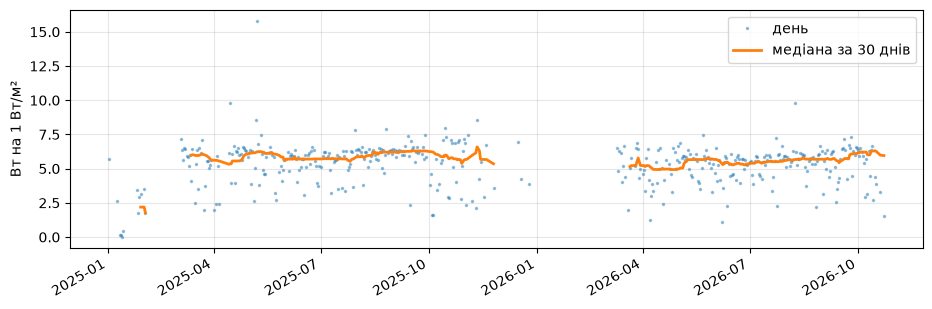

In [6]:
d = E.eff.groupby(loc.normalize()).median()
d = d[d.index >= pd.Timestamp(io.PANELS_SINCE, tz=io.TZ)]
roll = d.rolling('30D', min_periods=10).median()
ax = d.plot(style='.', ms=3, alpha=.4, label='день'); roll.plot(ax=ax, lw=2, label='медіана за 30 днів')
ax.set_ylabel('Вт на 1 Вт/м²'); ax.set_xlabel(''); ax.legend(); plt.show()

In [7]:
T2 = E.copy(); T2['temp'] = T2.archive__temperature_2m
T2['days'] = (T2.index - pd.Timestamp(io.PANELS_SINCE, tz='UTC')).days
# ефективність ~ час + температура + висота сонця: чи падає з часом, коли прибрати сезон
from numpy.linalg import lstsq
A = np.column_stack([np.ones(len(T2)), T2.days, T2.temp, np.sin(np.radians(T2.sun_elevation))])
c = lstsq(A, T2.eff, rcond=None)[0]
print(f"з урахуванням температури і висоти сонця: {c[1] * 365 / T2.eff.mean() * 100:+.1f} % на рік")
print(f"температура: {c[2] / T2.eff.mean() * 100:+.2f} % на градус (норма для кремнію ≈ −0.4)")

з урахуванням температури і висоти сонця: -3.0 % на рік
температура: +0.50 % на градус (норма для кремнію ≈ −0.4)


## 4. Нові ознаки — з ними і без них

Те, що відомо наперед з прогнозу погоди:
- **сніг на панелях** — проста модель: снігопад накопичується, тане від тепла (0.3 см на градус-годину) і від сонця навіть у легкий мороз;
- **днів після снігопаду**;
- **прогноз глибини снігу** (Open-Meteo);
- **іній / роса** — мінімум температури і максимум вологості за 12 год до години;
- **днів від початку роботи панелей** — для зношення. Попередження: дерева не вміють продовжувати тренд на майбутнє (бачать лише значення, що вже були), тож ця ознака навряд чи допоможе — перевіряємо, щоб знати напевно.

Кожен варіант — LightGBM, щомісяця перенавчання, + динамічна поправка; порівняння з повним набором (20 ознак).

In [8]:
PARAMS = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=0, verbose=-1)
fp = lambda X, yy, Xt: lgb.LGBMRegressor(**PARAMS).fit(X, yy).predict(Xt)
full = ev.variants()['повний (20 ознак)']
ADD = {'повний (20 ознак)': [],
       '+ сніг на панелях': ['snow_on_panels_cm'],
       '+ днів після снігопаду': ['days_since_snow'],
       '+ прогноз глибини снігу': ['forecast__snow_depth'],
       '+ іній / роса': ['night_min_temp', 'night_max_humidity'],
       '+ усе про сніг та іній': ['snow_on_panels_cm', 'days_since_snow', 'forecast__snow_depth', 'night_min_temp', 'night_max_humidity'],
       '+ днів від початку (зношення)': ['days_since_start']}
t = T.index; P = {}
for name, extra in ADD.items():
    b = ev.raw_all(df, fp, full + extra)
    P[name] = (b * ev.weighted_factor(b, y, 2)).reindex(t)
ref = P['повний (20 ознак)']
rows = {}
for k, v in P.items():
    m = ev.metrics(T.pv_w, v)
    win = T.index.tz_convert(io.TZ).month.isin([12, 1, 2, 3])
    rows[k] = {**{c: int(x) if c != 'nMAE, %' else x for c, x in m.items()},
               'промах взимку (гру–бер), Вт': int(ev.metrics(T.pv_w[win], v[win])['MAE, Вт']),
               'краще за повний, % вибірок': '—' if k.startswith('повний') else round(ev.daily_bootstrap(t, T.pv_w, v, ref) * 100)}
R = pd.DataFrame(rows).T; R.index.name = 'LightGBM + динамічна поправка'; R

,"MAE, Вт","nMAE, %","RMSE, Вт","зсув, Вт","промах взимку (гру–бер), Вт","краще за повний, % вибірок"
LightGBM + динамічна поправка,,,,,,
повний (20 ознак),302,25.0,502,16,253,—
+ сніг на панелях,301.0,24.9,499.0,8.0,255.0,75.0
+ днів після снігопаду,297.0,24.5,495.0,15.0,238.0,100.0
+ прогноз глибини снігу,298.0,24.7,495.0,8.0,245.0,97.0
+ іній / роса,301.0,24.9,493.0,15.0,255.0,71.0
+ усе про сніг та іній,296.0,24.5,491.0,8.0,235.0,98.0
+ днів від початку (зношення),311.0,25.7,507.0,21.0,254.0,1.0


In [9]:
pd.to_pickle({'days': D, 'features': R, 'preds': P}, io.DATA / 'errors.pkl')

## Висновки

1. **Найбільші помилки — від прогнозу погоди.** Коли прогноз сильно завищив сонце — модель завищує на 365 Вт; сильно занизив — занижує на 84. Найбільші промахи — при мінливій хмарності (індекс ясності 0.3–0.85: 429–464 Вт); у ясні й похмурі дні — 238–241. Це не виправити ознаками: моделі дали неправильну погоду.
2. **Систематичні помилки є — сніг і мороз.** Сніг на панелях 5+ см — факт / прогноз 0.78; день снігопаду — 0.70; ніч нижче −3° — 0.77. Модель там завищує на 60–110 Вт. Лютий 2026 — 0.65 (сніг і ожеледиця).
3. **Ознаки снігу та інею допомагають:** усі разом — 300 → **295 Вт**, краще у 95 % вибірок; взимку 250 → 230. Поодинці — найкорисніше «днів після снігопаду» (92 %). Беремо «усе про сніг та іній».
4. **О 13–14 модель трохи завищує** (факт / прогноз 0.89–0.94) — менше, ніж до очищення даних (там був провал від батареї).
5. **Незворотного зношення не видно.** Той самий місяць 2026 від 2025: бер 104 %, кві 86 %, тра 104 %, чер–вер 92–95 %, жов 110 %. Справжнє зношення йшло б лише вниз. Коливання схожі на бруд і пил (дощі відмивають). Лінійний тренд (−3 % на рік) ненадійний: з ним вийшло +0.5 % на градус, а для кремнію має бути −0.4.
6. **Ознака «днів від початку» шкодить** (310 Вт): дерева не вміють продовжувати тренд.
7. **Межа близько.** Решта промаху — прогноз погоди і бруд, які з погоди не видно. Далі: помити панелі навесні; поправка всередині дня.